=== 1. Dataset Overview ===
Total Records (Rows): 3395
Total Variables (Columns): 27

=== 2. Variable Types ===
Numerical Variables (6): ['Response', 'Order-type', 'Cycle-time', 'Manu-yield', 'Cap_ Utili', 'Relationship']

Categorical Variables (21): ['Shipment-route', 'ISO-Certi', 'Quali_ Award', 'Warranty', 'Quali_ Inspec', 'Quali_Reco', 'Quali_impro', 'Produ_Facility', 'Tech_Cap', 'Availability', 'Ex_rate', 'Commodity-price', 'Supplier-lock', 'Info-sharing', 'Nat-disasters', 'Man-Disaster', 'Politi-envir', 'Custom-Regu', 'Infrastructure', 'Eco_Situ', 'Supply_Risk']

--- Detailed Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 3395 entries, 0 to 3394
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Response         3395 non-null   int64
 1   Order-type       3395 non-null   int64
 2   Cycle-time       3395 non-null   int64
 3   Shipment-route   3395 non-null   str  
 4   ISO-Certi    

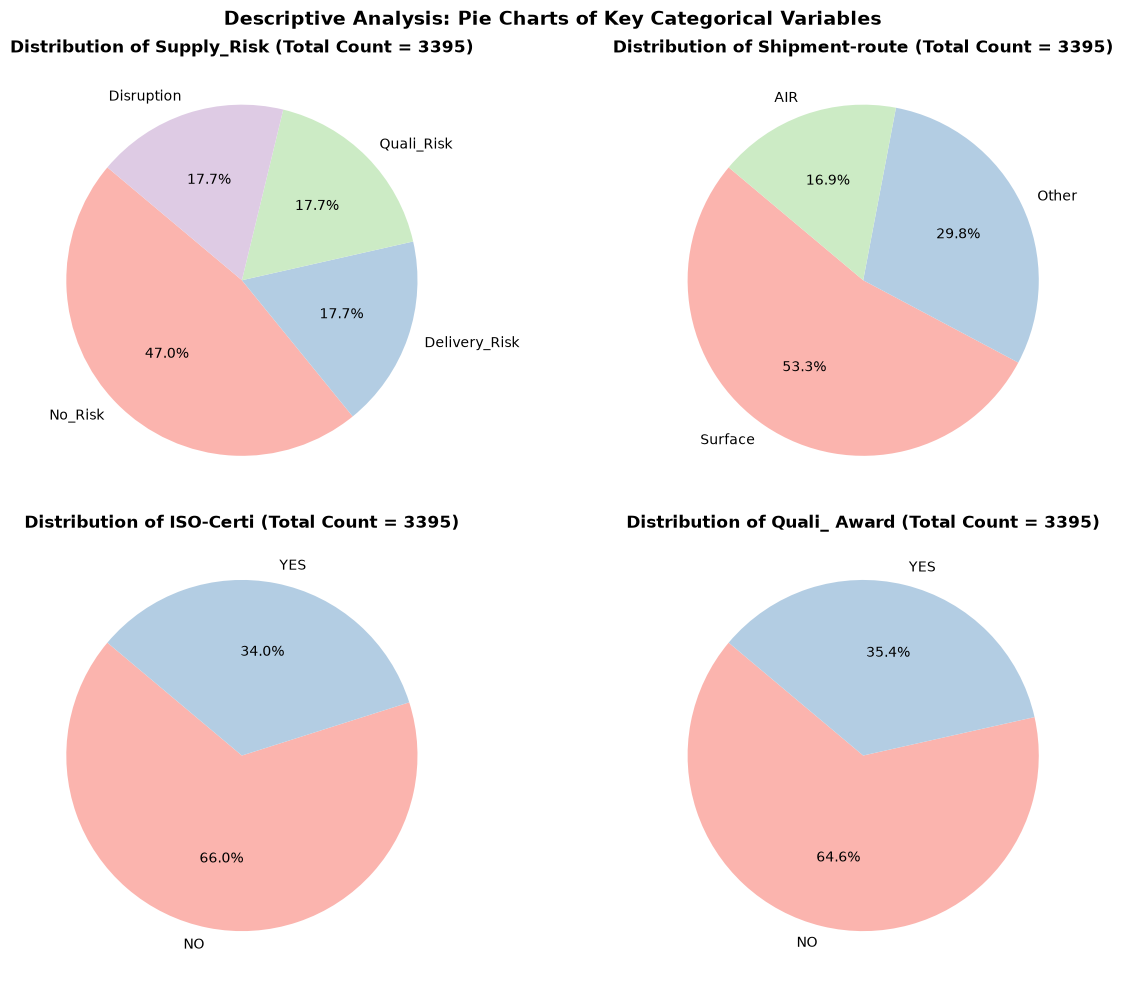

In [1]:
# ==========================================
# 0. Descriptive Statistics & Exploratory Data Analysis (EDA) - Clean Version
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_excel('SuppliersData.xlsx')
df.columns = df.columns.str.strip()

# 1. Total Records and Total Variables
print("=== 1. Dataset Overview ===")
print(f"Total Records (Rows): {df.shape[0]}")
print(f"Total Variables (Columns): {df.shape[1]}\n")

# 2. Variable Types Summary (Updated with 'str' to avoid warnings)
num_cols = df.select_dtypes(include=['number']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'str', 'category', 'bool']).columns.tolist()

print("=== 2. Variable Types ===")
print(f"Numerical Variables ({len(num_cols)}): {num_cols}")
print(f"\nCategorical Variables ({len(cat_cols)}): {cat_cols}\n")

print("--- Detailed Data Types & Non-Null Counts ---")
df.info()

# 3. Descriptive Statistics: Count, Mean, Min, and Max (Numerical Variables)
print("\n=== 3. Numerical Variables Summary (Count, Mean, Std, Min, Max) ===")
num_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', 'max']]
print(num_summary.to_string())

# 4. Descriptive Statistics: Count & Frequencies (Categorical Variables)
print("\n=== 4. Categorical Variables Summary (Count, Unique, Top, Frequency) ===")
cat_summary = df[cat_cols].describe().T
print(cat_summary.to_string())

# 5. Pie Charts for Target Variable & Key Categorical Features
pie_cols = ['Supply_Risk'] + [c for c in cat_cols if c != 'Supply_Risk' and 2 <= df[c].nunique() <= 6][:3]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for i, col in enumerate(pie_cols):
    counts = df[col].value_counts()
    axes[i].pie(
        counts, 
        labels=counts.index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=plt.cm.Pastel1.colors
    )
    axes[i].set_title(f'Distribution of {col} (Total Count = {counts.sum()})', fontweight='bold')

for j in range(len(pie_cols), 4):
    fig.delaxes(axes[j])

plt.suptitle('Descriptive Analysis: Pie Charts of Key Categorical Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


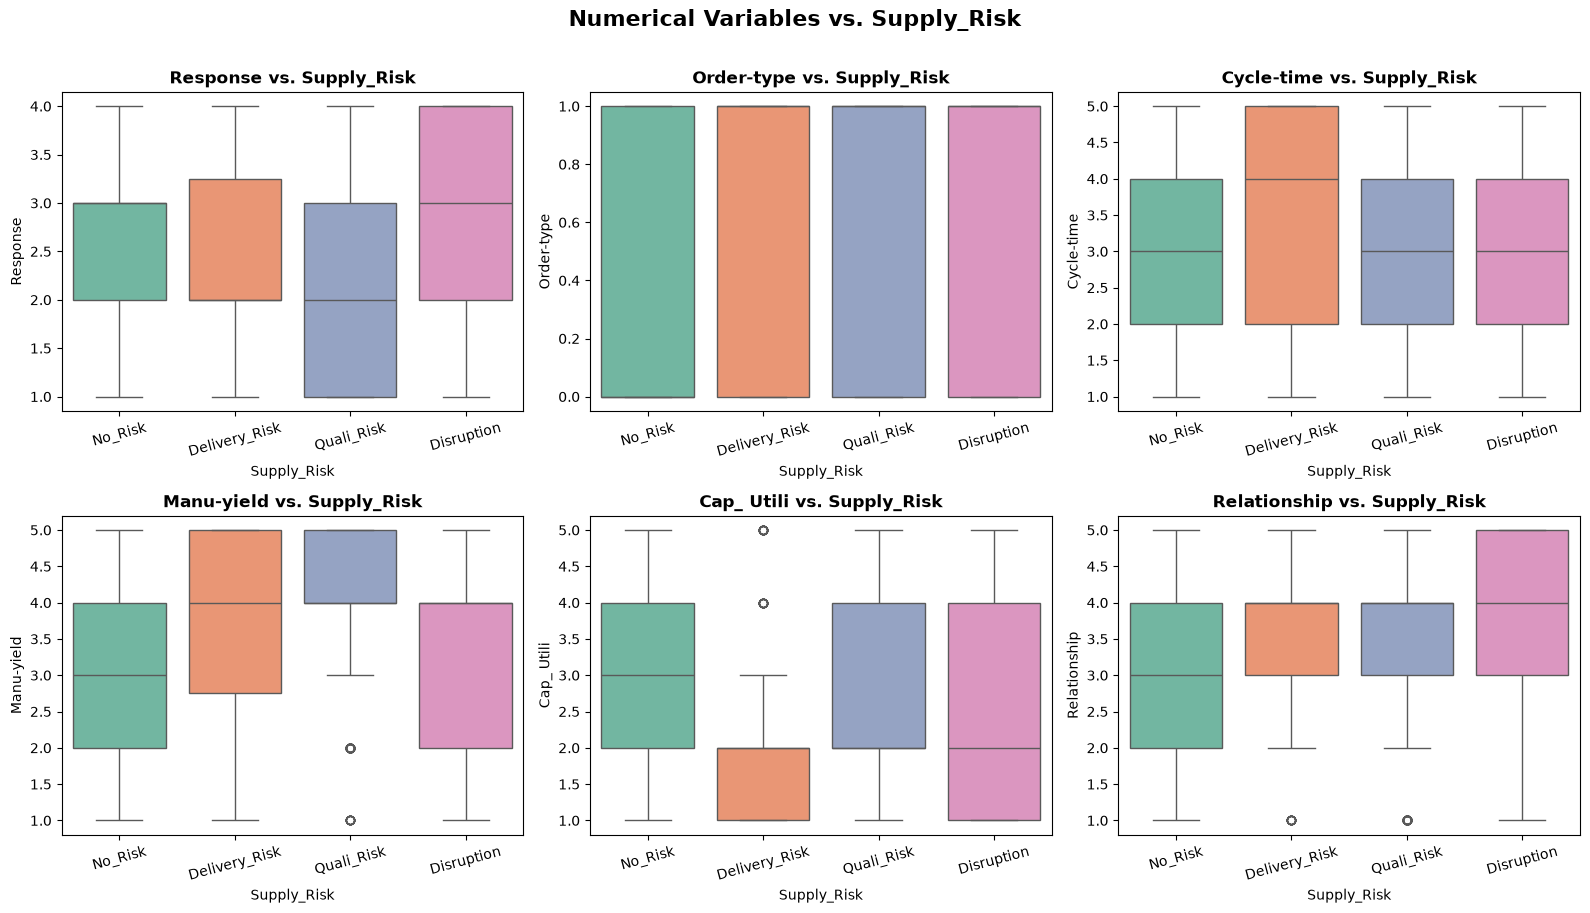

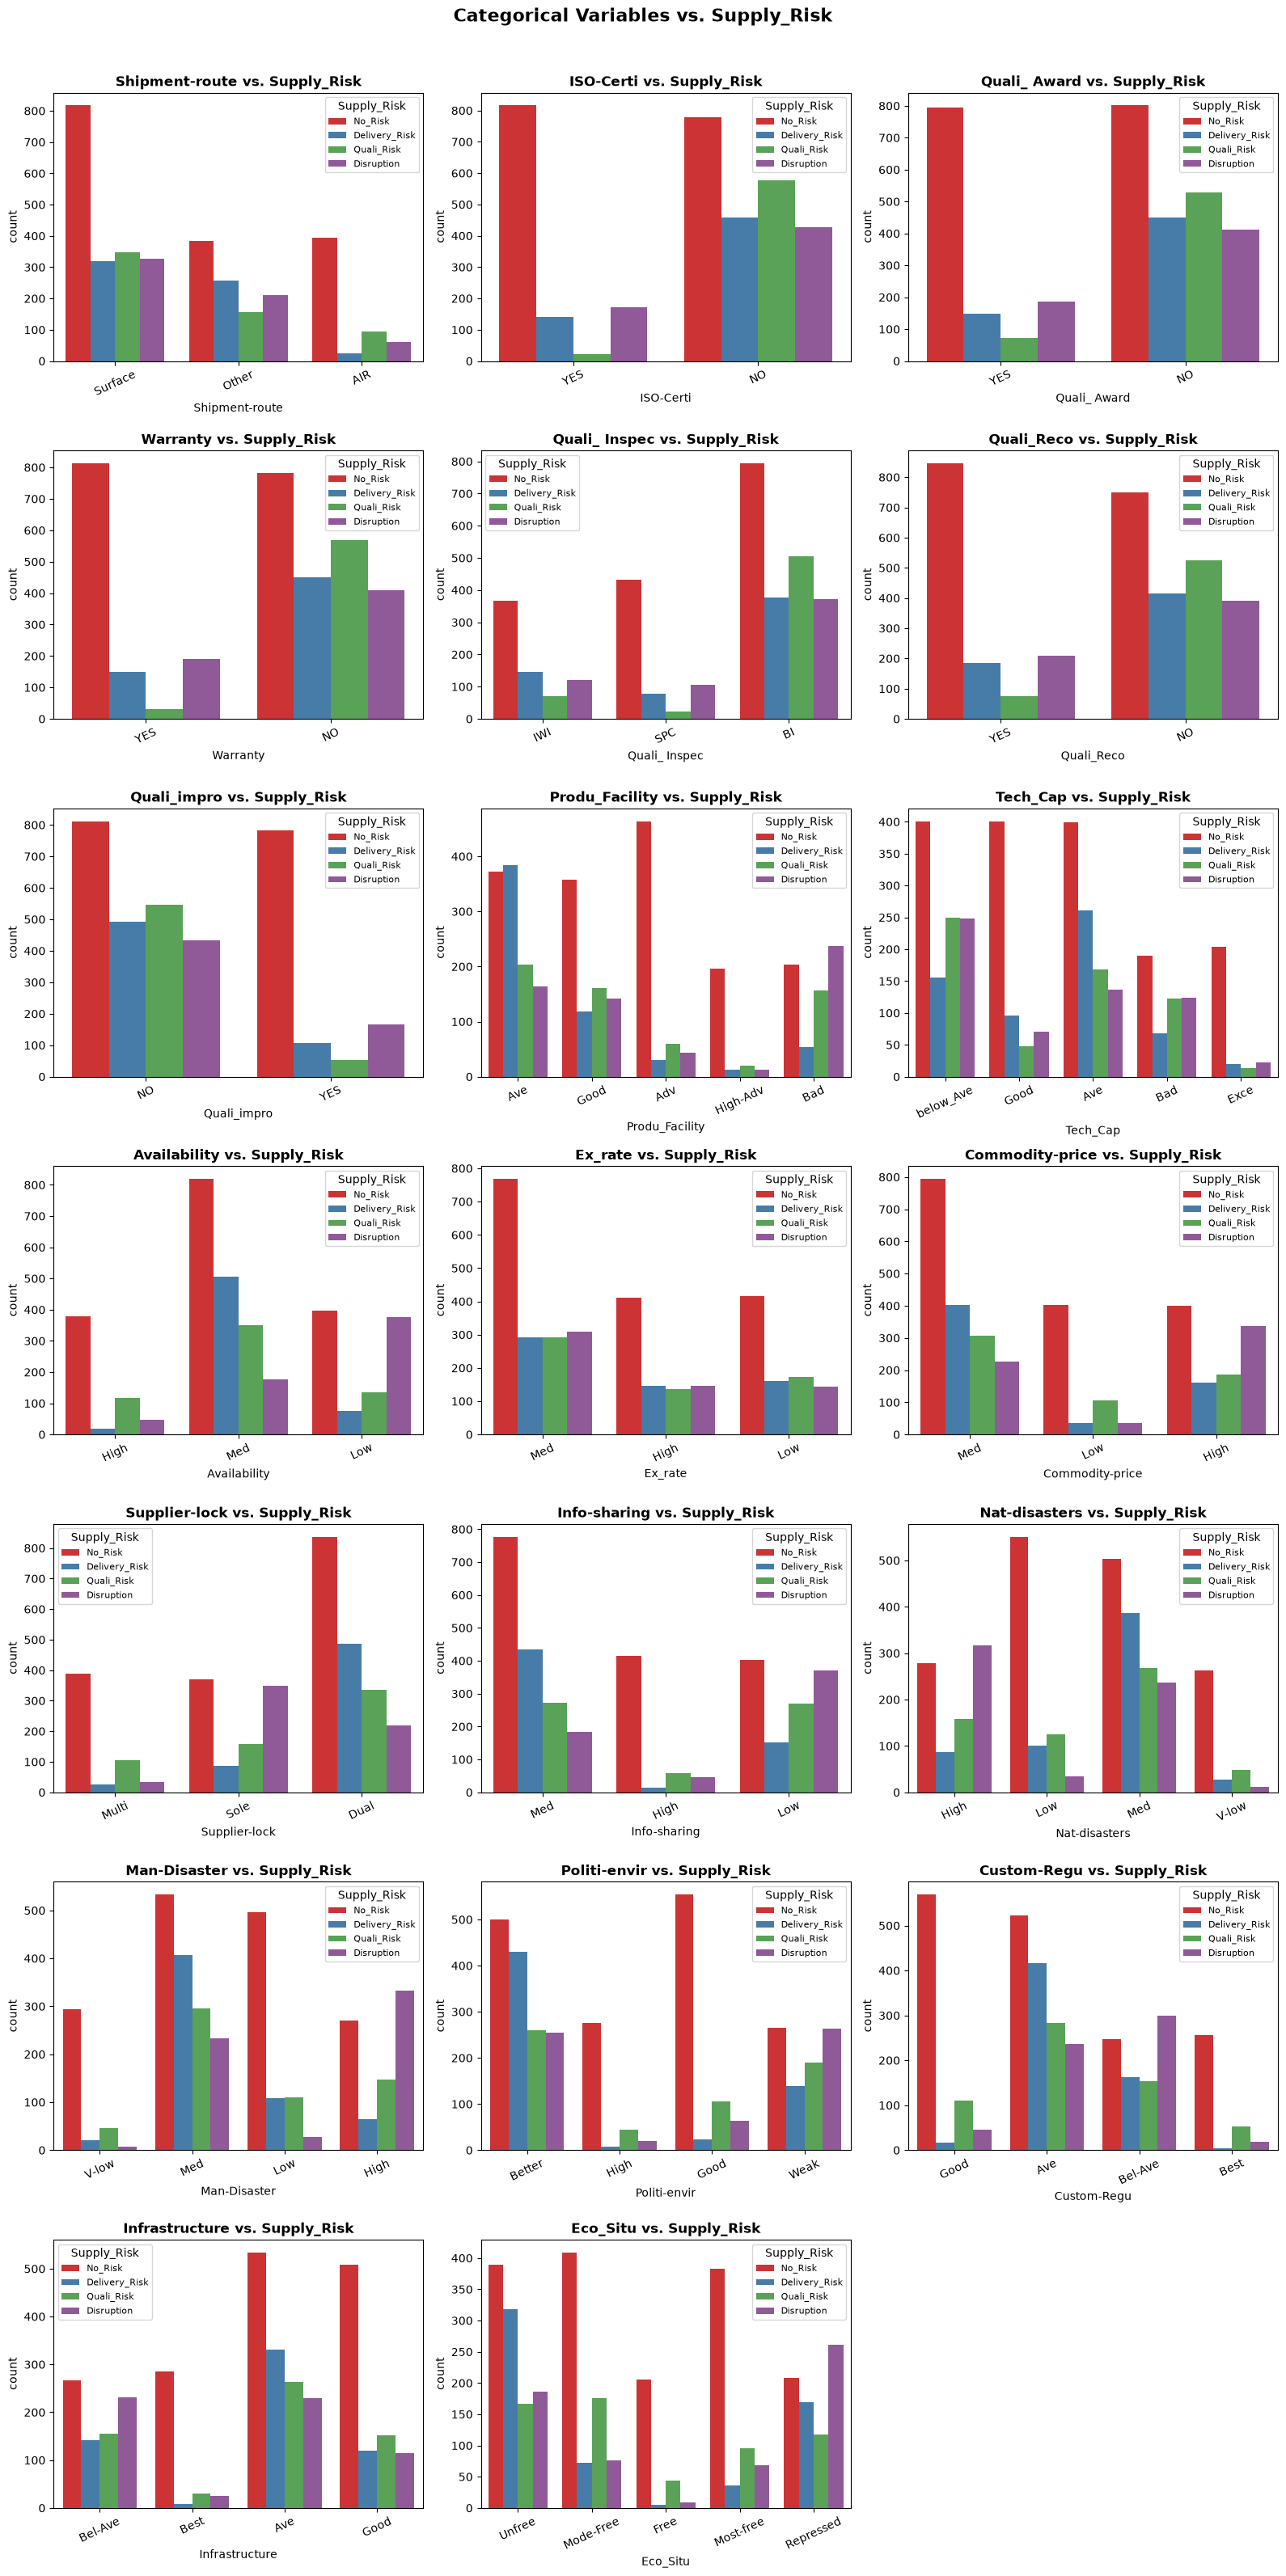

In [2]:
# ==========================================
# 0.2 Bivariate Analysis: Each Variable vs. Supply_Risk
# ==========================================
import math
import seaborn as sns
import matplotlib.pyplot as plt

# Get all feature columns excluding the target 'Supply_Risk'
features = [col for col in df.columns if col != 'Supply_Risk']

# Separate numerical and categorical features
num_features = df[features].select_dtypes(include=['number']).columns.tolist()
cat_features = df[features].select_dtypes(include=['object', 'str', 'category', 'bool']).columns.tolist()

# --- Part A: Numerical Variables vs. Supply_Risk (Boxplots) ---
if len(num_features) > 0:
    n_cols = 3
    n_rows = math.ceil(len(num_features) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(num_features):
        sns.boxplot(data=df, x='Supply_Risk', y=col, hue='Supply_Risk', palette='Set2', legend=False, ax=axes[i])
        axes[i].set_title(f'{col} vs. Supply_Risk', fontweight='bold')
        axes[i].tick_params(axis='x', rotation=15)

    for j in range(len(num_features), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle('Numerical Variables vs. Supply_Risk', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

# --- Part B: Categorical Variables vs. Supply_Risk (Countplots) ---
if len(cat_features) > 0:
    n_cols = 3
    n_rows = math.ceil(len(cat_features) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(cat_features):
        sns.countplot(data=df, x=col, hue='Supply_Risk', palette='Set1', ax=axes[i])
        axes[i].set_title(f'{col} vs. Supply_Risk', fontweight='bold')
        axes[i].tick_params(axis='x', rotation=25)
        axes[i].legend(title='Supply_Risk', fontsize=8)

    for j in range(len(cat_features), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle('Categorical Variables vs. Supply_Risk', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


Dataset Shape: (3395, 27)

Target Variable Distribution (Supply_Risk):
Supply_Risk
No_Risk          1595
Delivery_Risk     600
Quali_Risk        600
Disruption        600
Name: count, dtype: int64

Model Accuracy: 96.32%

Classification Report:

               precision    recall  f1-score   support

Delivery_Risk       0.95      0.95      0.95       120
   Disruption       0.94      0.97      0.96       120
      No_Risk       0.99      0.98      0.99       319
   Quali_Risk       0.92      0.91      0.91       120

     accuracy                           0.96       679
    macro avg       0.95      0.95      0.95       679
 weighted avg       0.96      0.96      0.96       679



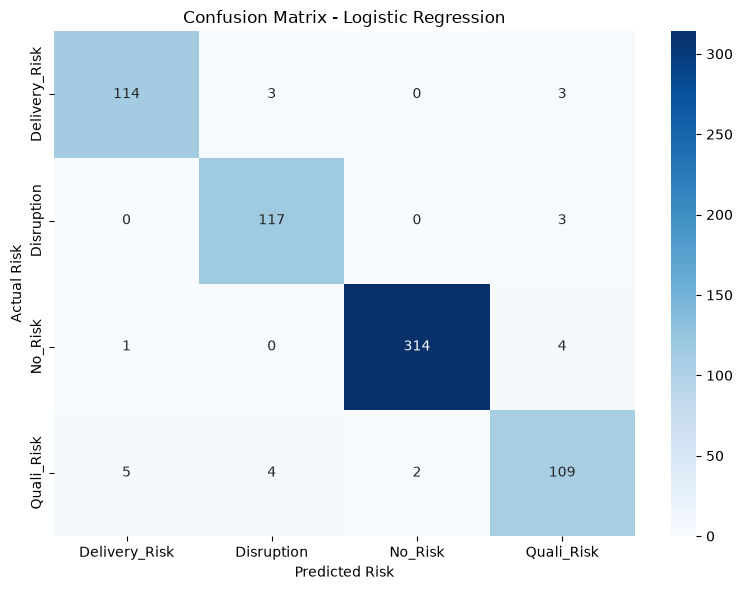

In [3]:
# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 2. Load the Excel Dataset
df = pd.read_excel('SuppliersData.xlsx')

# Clean any accidental leading/trailing spaces in column names
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\nTarget Variable Distribution (Supply_Risk):")
print(df['Supply_Risk'].value_counts())

# 3. Data Preprocessing
X = df.drop('Supply_Risk', axis=1)
y = df['Supply_Risk']

# Convert categorical text columns into numeric dummy variables (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# Split data: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Build and Train Logistic Regression Model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 5. Model Prediction & Evaluation
y_pred = log_reg.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=log_reg.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=log_reg.classes_, 
            yticklabels=log_reg.classes_)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')
plt.tight_layout()
plt.show()


Neural Network Accuracy: 94.55%

Classification Report (Neural Network):

               precision    recall  f1-score   support

Delivery_Risk       0.92      0.93      0.93       120
   Disruption       0.92      0.93      0.93       120
      No_Risk       0.98      0.97      0.98       319
   Quali_Risk       0.90      0.90      0.90       120

     accuracy                           0.95       679
    macro avg       0.93      0.93      0.93       679
 weighted avg       0.95      0.95      0.95       679



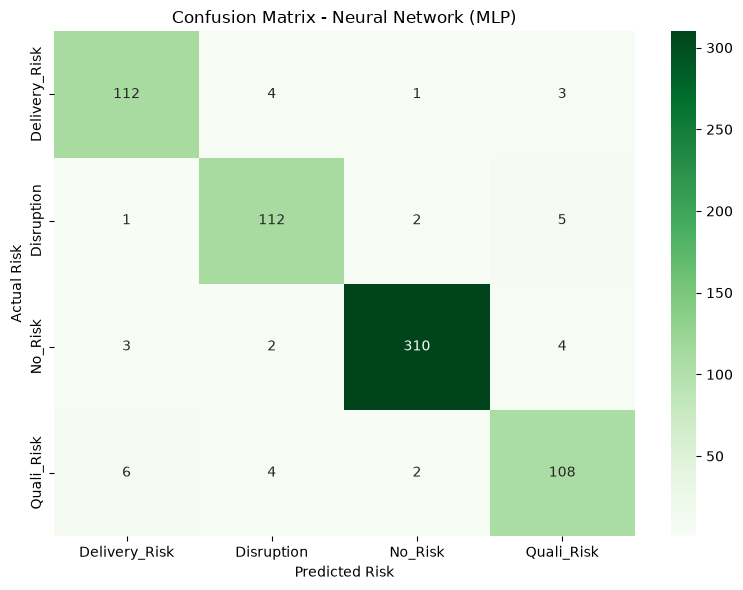

In [4]:
# ==========================================
# Neural Network (MLPClassifier) Model
# ==========================================
from sklearn.neural_network import MLPClassifier

# Build and train the Neural Network model
# hidden_layer_sizes=(64, 32) creates 2 hidden layers with 64 and 32 neurons
nn_model = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
nn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nn = nn_model.predict(X_test_scaled)

# Evaluate the Neural Network model
nn_accuracy = accuracy_score(y_test, y_pred_nn)
print(f"Neural Network Accuracy: {nn_accuracy * 100:.2f}%\n")
print("Classification Report (Neural Network):\n")
print(classification_report(y_test, y_pred_nn))

# Plot Confusion Matrix for Neural Network
cm_nn = confusion_matrix(y_test, y_pred_nn, labels=nn_model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Greens', 
            xticklabels=nn_model.classes_, 
            yticklabels=nn_model.classes_)
plt.title('Confusion Matrix - Neural Network (MLP)')
plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')
plt.tight_layout()
plt.show()


Decision Tree Accuracy: 64.06%

Classification Report (Decision Tree):

               precision    recall  f1-score   support

Delivery_Risk       0.58      0.71      0.64       120
   Disruption       0.47      0.48      0.48       120
      No_Risk       0.81      0.74      0.77       319
   Quali_Risk       0.48      0.47      0.47       120

     accuracy                           0.64       679
    macro avg       0.58      0.60      0.59       679
 weighted avg       0.65      0.64      0.64       679



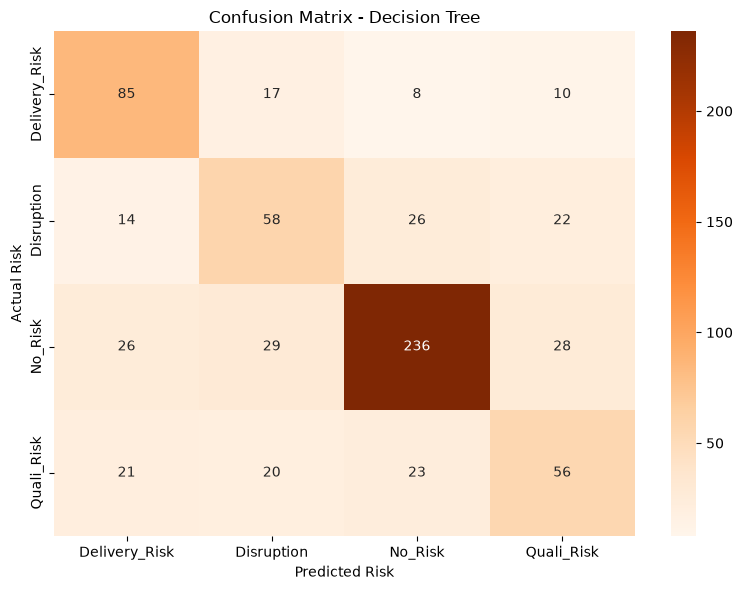

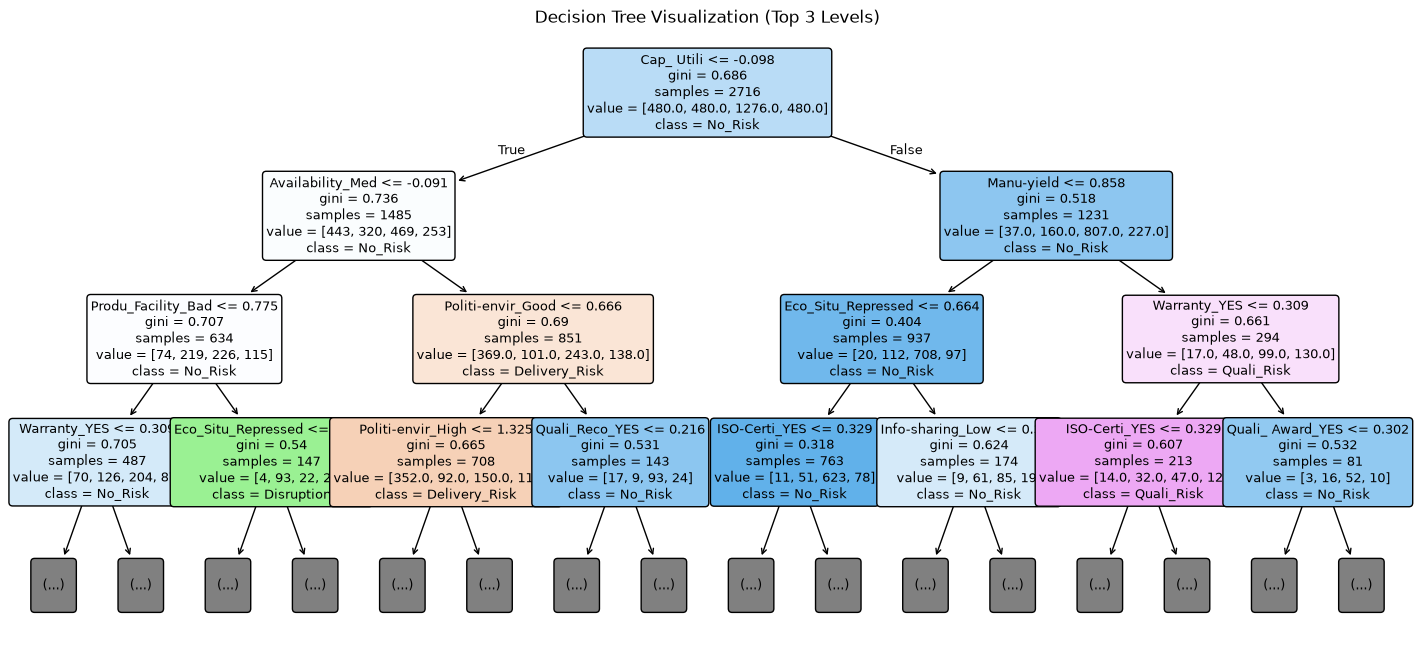

In [5]:
# ==========================================
# 3. Decision Tree Classifier Model
# ==========================================
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Build and train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate the Decision Tree model
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%\n")
print("Classification Report (Decision Tree):\n")
print(classification_report(y_test, y_pred_dt))

# Plot Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=dt_model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=dt_model.classes_, 
            yticklabels=dt_model.classes_)
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')
plt.tight_layout()
plt.show()

# Plot a simplified view of the Decision Tree (Top 3 levels for clarity)
plt.figure(figsize=(18, 8))
plot_tree(dt_model, max_depth=3, feature_names=X_encoded.columns, 
          class_names=dt_model.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Visualization (Top 3 Levels)')
plt.show()


Bayesian Classifier (Naive Bayes) Accuracy: 81.74%

Classification Report (Bayesian Classifier):

               precision    recall  f1-score   support

Delivery_Risk       0.73      0.77      0.75       120
   Disruption       0.74      0.81      0.77       120
      No_Risk       0.90      0.91      0.90       319
   Quali_Risk       0.75      0.64      0.69       120

     accuracy                           0.82       679
    macro avg       0.78      0.78      0.78       679
 weighted avg       0.82      0.82      0.82       679



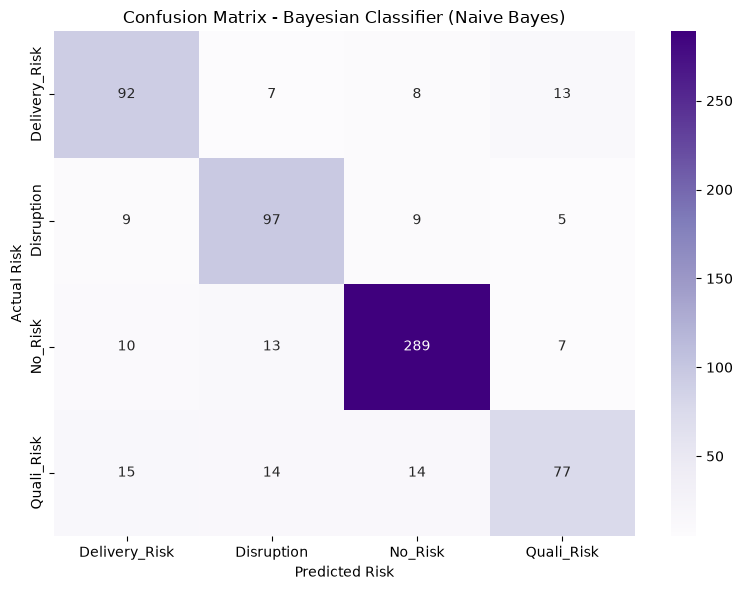

In [6]:
# ==========================================
# 4. Bayesian Classifier (Gaussian Naive Bayes)
# ==========================================
from sklearn.naive_bayes import GaussianNB

# Build and train the Bayesian Classifier model
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_scaled)

# Evaluate the Bayesian model
nb_accuracy = accuracy_score(y_test, y_pred_nb)
print(f"Bayesian Classifier (Naive Bayes) Accuracy: {nb_accuracy * 100:.2f}%\n")
print("Classification Report (Bayesian Classifier):\n")
print(classification_report(y_test, y_pred_nb))

# Plot Confusion Matrix for Bayesian Classifier
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=nb_model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Purples', 
            xticklabels=nb_model.classes_, 
            yticklabels=nb_model.classes_)
plt.title('Confusion Matrix - Bayesian Classifier (Naive Bayes)')
plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')
plt.tight_layout()
plt.show()


=== Model Comparison Summary ===
                        Algorithm  Accuracy (%)
              Logistic Regression     96.318115
             Neural Network (MLP)     94.550810
Bayesian Classifier (Naive Bayes)     81.737850
                    Decision Tree     64.064801


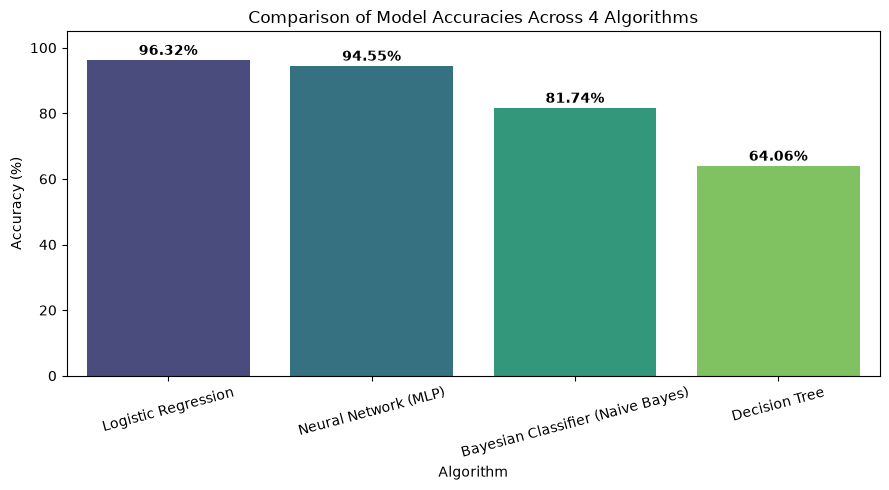

In [7]:
# ==========================================
# 5. Final Comparison of All 4 Algorithms (Clean Version)
# ==========================================
results = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression', 
        'Neural Network (MLP)', 
        'Bayesian Classifier (Naive Bayes)',
        'Decision Tree'
    ],
    'Accuracy (%)': [
        accuracy * 100, 
        nn_accuracy * 100, 
        nb_accuracy * 100,
        dt_accuracy * 100
    ]
}).sort_values(by='Accuracy (%)', ascending=False)

print("=== Model Comparison Summary ===")
print(results.to_string(index=False))

# Bar Chart Comparison without warnings
plt.figure(figsize=(9, 5))
sns.barplot(data=results, x='Algorithm', y='Accuracy (%)', hue='Algorithm', palette='viridis', legend=False)
plt.title('Comparison of Model Accuracies Across 4 Algorithms')
plt.ylim(0, 105)
for index, row in enumerate(results['Accuracy (%)']):
    plt.text(index, row + 1.5, f"{row:.2f}%", ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [8]:
# ==========================================
# Save Trained Logistic Regression Model & Artifacts
# ==========================================
import joblib

# Save the best model (Logistic Regression), scaler, column names, and original dataframe structure
model_artifacts = {
    'model': log_reg,
    'scaler': scaler,
    'encoded_columns': X_encoded.columns.tolist(),
    'feature_names': X.columns.tolist(),
    'num_cols': X.select_dtypes(include=['number']).columns.tolist(),
    'cat_options': {col: sorted(df[col].unique().tolist()) for col in X.select_dtypes(exclude=['number']).columns}
}

joblib.dump(model_artifacts, 'supply_risk_model.pkl')
print("Model saved successfully as 'supply_risk_model.pkl'!")


Model saved successfully as 'supply_risk_model.pkl'!


In [9]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

# Page Configuration
st.set_page_config(page_title="Supply Risk Prediction System", layout="wide")

# Load saved model and artifacts
artifacts = joblib.load('supply_risk_model.pkl')
model = artifacts['model']
scaler = artifacts['scaler']
encoded_columns = artifacts['encoded_columns']
feature_names = artifacts['feature_names']
num_cols = artifacts['num_cols']
cat_options = artifacts['cat_options']

# Header Section
st.title("Supplier Supply Risk Prediction System")
st.markdown("""
This interactive web application utilizes a **Multinomial Logistic Regression** model (**96.32% Accuracy**) 
to predict potential supply chain risks based on supplier attributes.
""")
st.divider()

# User Input Form with Drop-downs and Number Inputs
st.subheader("1. Select Supplier Attributes")

user_inputs = {}
cols = st.columns(3)  # Organize inputs cleanly into 3 columns

for i, col_name in enumerate(feature_names):
    with cols[i % 3]:
        if col_name in cat_options:
            # Create a Drop-down menu for categorical variables
            user_inputs[col_name] = st.selectbox(
                label=f"{col_name}",
                options=cat_options[col_name]
            )
        else:
            # Create a numeric input box for numerical variables
            user_inputs[col_name] = st.number_input(
                label=f"{col_name}",
                value=0.0,
                step=1.0
            )

st.divider()

# Prediction Button & Output
if st.button("Predict Supply Risk", type="primary", use_container_width=True):
    # Convert user inputs into a single-row DataFrame
    input_df = pd.DataFrame([user_inputs])
    
    # Apply the exact same One-Hot Encoding and column alignment used in training
    input_encoded = pd.get_dummies(input_df, drop_first=True)
    input_encoded = input_encoded.reindex(columns=encoded_columns, fill_value=0)
    
    # Scale numerical features
    input_scaled = scaler.transform(input_encoded)
    
    # Make prediction and get probabilities
    prediction = model.predict(input_scaled)[0]
    probabilities = model.predict_proba(input_scaled)[0]
    
    # Display Result
    st.subheader("2. Prediction Outcome")
    if prediction == "No_Risk":
        st.success(f"Predicted Outcome: {prediction} (Low or No Supply Chain Risk)")
    else:
        st.error(f"Predicted Outcome: {prediction} (High Risk Detected)")
    
    # Display Probability Breakdown Chart
    prob_df = pd.DataFrame({
        'Risk Category': model.classes_,
        'Probability (%)': probabilities * 100
    }).sort_values(by='Probability (%)', ascending=False)
    
    st.write("**Prediction Confidence Breakdown:**")
    st.bar_chart(prob_df.set_index('Risk Category'))


Overwriting app.py


In [10]:
%%writefile requirements.txt
streamlit
pandas
scikit-learn
joblib
openpyxl


Overwriting requirements.txt


In [11]:
# ==========================================
# Update Saved Model Artifacts with Min/Max Ranges & Exact Options
# ==========================================
import joblib

num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()

# Also treat numeric columns with very few unique values (<= 10) as dropdowns if appropriate, 
# or keep pure numeric columns with strict min/max bounds from the dataset
num_bounds = {}
for col in num_cols:
    num_bounds[col] = {
        'min': float(df[col].min()),
        'max': float(df[col].max()),
        'median': float(df[col].median()),
        'is_int': pd.api.types.is_integer_dtype(df[col])
    }

model_artifacts = {
    'model': log_reg,
    'scaler': scaler,
    'encoded_columns': X_encoded.columns.tolist(),
    'feature_names': X.columns.tolist(),
    'num_cols': num_cols,
    'num_bounds': num_bounds,
    'cat_options': {col: sorted(df[col].dropna().unique().tolist()) for col in cat_cols}
}

joblib.dump(model_artifacts, 'supply_risk_model.pkl')
print("Updated 'supply_risk_model.pkl' with exact Min/Max bounds successfully!")


Updated 'supply_risk_model.pkl' with exact Min/Max bounds successfully!


In [12]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

# Page Configuration
st.set_page_config(page_title="Supply Risk Prediction System", layout="wide")

# Load saved model and artifacts
artifacts = joblib.load('supply_risk_model.pkl')
model = artifacts['model']
scaler = artifacts['scaler']
encoded_columns = artifacts['encoded_columns']
feature_names = artifacts['feature_names']
num_bounds = artifacts['num_bounds']
cat_options = artifacts['cat_options']

# Header Section
st.title("Supplier Supply Risk Prediction System")
st.markdown("""
This interactive web application utilizes a **Multinomial Logistic Regression** model (**96.32% Accuracy**) 
to predict potential supply chain risks based on supplier attributes.
""")
st.divider()

# User Input Form with Drop-downs and Bounded Numeric Inputs
st.subheader("1. Select Supplier Attributes")

user_inputs = {}
cols = st.columns(3)

for i, col_name in enumerate(feature_names):
    with cols[i % 3]:
        if col_name in cat_options:
            # Drop-down menu restricted strictly to values present in the dataset
            user_inputs[col_name] = st.selectbox(
                label=f"{col_name}",
                options=cat_options[col_name]
            )
        else:
            # Numeric input showing and enforcing exact Min and Max values from the dataset
            bounds = num_bounds[col_name]
            min_val = bounds['min']
            max_val = bounds['max']
            default_val = bounds['median']
            
            if bounds['is_int']:
                user_inputs[col_name] = st.number_input(
                    label=f"{col_name} (Min: {int(min_val)}, Max: {int(max_val)})",
                    min_value=int(min_val),
                    max_value=int(max_val),
                    value=int(default_val),
                    step=1
                )
            else:
                user_inputs[col_name] = st.number_input(
                    label=f"{col_name} (Min: {min_val:.2f}, Max: {max_val:.2f})",
                    min_value=float(min_val),
                    max_value=float(max_val),
                    value=float(default_val),
                    step=0.1
                )

st.divider()

# Prediction Button & Output
if st.button("Predict Supply Risk", type="primary", use_container_width=True):
    # Convert user inputs into a single-row DataFrame
    input_df = pd.DataFrame([user_inputs])
    
    # Apply the exact same One-Hot Encoding and column alignment used in training
    input_encoded = pd.get_dummies(input_df, drop_first=True)
    input_encoded = input_encoded.reindex(columns=encoded_columns, fill_value=0)
    
    # Scale numerical features
    input_scaled = scaler.transform(input_encoded)
    
    # Make prediction and get probabilities
    prediction = model.predict(input_scaled)
    probabilities = model.predict_proba(input_scaled)
    
    # Display Result
    st.subheader("2. Prediction Outcome")
    if prediction == "No_Risk":
        st.success(f"Predicted Outcome: {prediction} (Low or No Supply Chain Risk)")
    else:
        st.error(f"Predicted Outcome: {prediction} (High Risk Detected)")
    
    # Display Probability Breakdown Chart
    prob_df = pd.DataFrame({
        'Risk Category': model.classes_,
        'Probability (%)': probabilities * 100
    }).sort_values(by='Probability (%)', ascending=False)
    
    st.write("**Prediction Confidence Breakdown:**")
    st.bar_chart(prob_df.set_index('Risk Category'))


Overwriting app.py


In [13]:
# ==========================================
# Update Saved Model Artifacts for Dropdown Menus
# ==========================================
import joblib

num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()

# Store exact sorted unique values for every column (both numeric and categorical)
dropdown_options = {}
for col in X.columns:
    unique_vals = sorted(df[col].dropna().unique().tolist())
    dropdown_options[col] = unique_vals

model_artifacts = {
    'model': log_reg,
    'scaler': scaler,
    'encoded_columns': X_encoded.columns.tolist(),
    'feature_names': X.columns.tolist(),
    'dropdown_options': dropdown_options
}

joblib.dump(model_artifacts, 'supply_risk_model.pkl')
print("Updated 'supply_risk_model.pkl' with dropdown options for all variables!")


Updated 'supply_risk_model.pkl' with dropdown options for all variables!


In [14]:

%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

# Page Configuration
st.set_page_config(page_title="Supply Risk Prediction System", layout="wide")

# Load saved model and artifacts
artifacts = joblib.load('supply_risk_model.pkl')
model = artifacts['model']
scaler = artifacts['scaler']
encoded_columns = artifacts['encoded_columns']
feature_names = artifacts['feature_names']
dropdown_options = artifacts['dropdown_options']

# Clean readable labels for the 4 risk outcomes
risk_labels = {
    "No_Risk": "No Risk (Safe Supply Chain Operation)",
    "Delivery_Risk": "Delivery Risk (Potential Delay in Shipment)",
    "Quali_Risk": "Quality Risk (Potential Product Defect or Standard Issue)",
    "Disruption": "Supply Disruption (High Risk of Supply Interruption)"
}

# Header Section
st.title("Supplier Supply Risk Prediction System")
st.markdown("""
This interactive web application utilizes a **Multinomial Logistic Regression** model (**96.32% Accuracy**) 
to predict potential supply chain risks based on supplier attributes.
""")
st.divider()

# User Input Form - All variables presented as clean Drop-down Menus
st.subheader("1. Select Supplier Attributes")

user_inputs = {}
cols = st.columns(3)

for i, col_name in enumerate(feature_names):
    with cols[i % 3]:
        options = dropdown_options[col_name]
        min_val, max_val = options, options[-1]
        
        # Show Min and Max in label for numeric columns
        if isinstance(min_val, (int, float)):
            label_text = f"{col_name} (Range: {min_val} to {max_val})"
        else:
            label_text = f"{col_name}"
            
        user_inputs[col_name] = st.selectbox(
            label=label_text,
            options=options
        )

st.divider()

# Prediction Button & Clean Output
if st.button("Predict Supply Risk", type="primary", use_container_width=True):
    # Convert user inputs into a single-row DataFrame
    input_df = pd.DataFrame([user_inputs])
    
    # Apply the exact same One-Hot Encoding and column alignment used in training
    input_encoded = pd.get_dummies(input_df, drop_first=True)
    input_encoded = input_encoded.reindex(columns=encoded_columns, fill_value=0)
    
    # Scale numerical features
    input_scaled = scaler.transform(input_encoded)
    
    # Extract single clean string prediction (removes brackets [''])
    pred_code = str(model.predict(input_scaled))
    readable_result = risk_labels.get(pred_code, pred_code)
    probabilities = model.predict_proba(input_scaled)
    
    # Display Result cleanly
    st.subheader("2. Prediction Outcome")
    if pred_code == "No_Risk":
        st.success(f"Predicted Status: {readable_result}")
    else:
        st.error(f"Alert - Predicted Status: {readable_result}")
    
    # Display Probability Breakdown Chart
    prob_df = pd.DataFrame({
        'Risk Category': [risk_labels.get(c, c) for c in model.classes_],
        'Probability (%)': probabilities * 100
    }).sort_values(by='Probability (%)', ascending=False)
    
    st.write("**Prediction Confidence Breakdown:**")
    st.bar_chart(prob_df.set_index('Risk Category'))


Overwriting app.py


In [15]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="Supply Risk Prediction System", layout="wide")

artifacts = joblib.load('supply_risk_model.pkl')
model = artifacts['model']
scaler = artifacts['scaler']
encoded_columns = artifacts['encoded_columns']
feature_names = artifacts['feature_names']
dropdown_options = artifacts['dropdown_options']

feature_metadata = {
    "Response": {
        "title": "Supplier Response Time",
        "desc": "Time taken by the supplier to respond to inquiries or orders (1 = 1 day, 4 = >7 days).",
        "labels": {1: "1 (Within 1 day)", 2: "2 (1–3 days)", 3: "3 (4–7 days)", 4: "4 (More than 7 days)"}
    },
    "Order-type": {
        "title": "Order Type",
        "desc": "Nature of the purchase order (0 = New order, 1 = Repetitive order).",
        "labels": {0: "0 (New Order)", 1: "1 (Repetitive Order)"}
    },
    "Cycle-time": {
        "title": "Order Cycle Time",
        "desc": "Total lead time from order placement to delivery (1 = Within 1 week, 5 = >12 weeks).",
        "labels": {1: "1 (Within 1 week)", 2: "2 (2–4 weeks)", 3: "3 (5–8 weeks)", 4: "4 (9–12 weeks)", 5: "5 (More than 12 weeks)"}
    },
    "Shipment-route": {
        "title": "Shipment Route",
        "desc": "Primary transportation mode used for delivery (Air, Surface/Land, or Other).",
        "labels": {"AIR": "AIR (Air Freight)", "Surface": "Surface (Land/Sea)", "Other": "Other"}
    },
    "ISO-Certi": {
        "title": "ISO Certification",
        "desc": "Indicates whether the supplier holds valid ISO quality/management certifications.",
        "labels": {"YES": "YES (Certified)", "NO": "NO (Not Certified)"}
    },
    "Quali_ Award": {
        "title": "Quality Awards",
        "desc": "Indicates whether the supplier has received recognized industry quality awards.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Manu-yield": {
        "title": "Manufacturing Yield Rate",
        "desc": "Percentage of defect-free units produced (1 = 91–100% highest yield, 5 = <60% lowest yield).",
        "labels": {1: "1 (91–100%)", 2: "2 (81–90%)", 3: "3 (71–80%)", 4: "4 (61–70%)", 5: "5 (Below 60%)"}
    },
    "Warranty": {
        "title": "Product Warranty",
        "desc": "Indicates whether the supplier provides warranty coverage on supplied products.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Quali_ Inspec": {
        "title": "Quality Inspection Method",
        "desc": "Inspection method applied: Statistical Process Control (SPC), Batch Inspection (BI), or In-Work Inspection (IWI).",
        "labels": {"SPC": "SPC (Statistical Process Control)", "BI": "BI (Batch Inspection)", "IWI": "IWI (In-Work Inspection)"}
    },
    "Quali_Reco": {
        "title": "Quality Documentation & Records",
        "desc": "Indicates whether the supplier maintains formal quality control records and documentation.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Quali_impro": {
        "title": "Quality Improvement Programs",
        "desc": "Indicates whether the supplier actively implements continuous quality improvement initiatives.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Produ_Facility": {
        "title": "Production Facility Level",
        "desc": "Condition and modernization level of manufacturing facilities (High-Adv to Bad).",
        "labels": {"High-Adv": "High-Adv (Highly Advanced)", "Adv": "Adv (Advanced)", "Good": "Good", "Ave": "Ave (Average)", "Bad": "Bad"}
    },
    "Tech_Cap": {
        "title": "Technical Capabilities",
        "desc": "Engineering and technical expertise level of the supplier (Exce to Bad).",
        "labels": {"Exce": "Exce (Excellent)", "Good": "Good", "Ave": "Ave (Average)", "below_Ave": "below_Ave (Below Average)", "Bad": "Bad"}
    },
    "Cap_ Utili": {
        "title": "Capacity Utilization",
        "desc": "Proportion of total production capacity currently utilized (1 = 91–100%, 5 = <60%).",
        "labels": {1: "1 (91–100%)", 2: "2 (81–90%)", 3: "3 (71–80%)", 4: "4 (61–70%)", 5: "5 (Below 60%)"}
    },
    "Availability": {
        "title": "Market Supply Availability",
        "desc": "Availability of alternative suppliers or materials in the market (High, Medium, Low).",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Ex_rate": {
        "title": "Exchange Rate Volatility",
        "desc": "Level of currency exchange rate fluctuation affecting procurement costs.",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Commodity-price": {
        "title": "Commodity Price Volatility",
        "desc": "Degree of raw material and commodity price instability.",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Relationship": {
        "title": "Supplier Relationship Duration",
        "desc": "Length of business partnership with the supplier (1 = >5 years, 5 = New supplier).",
        "labels": {1: "1 (Above 5 years)", 2: "2 (4–5 years)", 3: "3 (2–3 years)", 4: "4 (1 year)", 5: "5 (New supplier)"}
    },
    "Supplier-lock": {
        "title": "Sourcing Strategy (Supplier Lock-in)",
        "desc": "Dependency structure on the supplier (Sole, Dual, or Multiple sources).",
        "labels": {"Sole": "Sole (Single Supplier)", "Dual": "Dual (Two Suppliers)", "Multi": "Multi (Multiple Suppliers)"}
    },
    "Info-sharing": {
        "title": "Information Sharing Level",
        "desc": "Transparency and frequency of operational data sharing with the supplier.",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Nat-disasters": {
        "title": "Natural Disasters Risk",
        "desc": "Exposure of the supplier's region to natural disasters (High to V-low).",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low", "V-low": "V-low (Very Low)"}
    },
    "Man-Disaster": {
        "title": "Man-Made Disasters Risk",
        "desc": "Exposure to operational accidents, strikes, or man-made disruptions (High to V-low).",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low", "V-low": "V-low (Very Low)"}
    },
    "Politi-envir": {
        "title": "Political Environment Stability",
        "desc": "Political stability in the supplier's operating country or region.",
        "labels": {"High": "High", "Better": "Better", "Good": "Good", "Weak": "Weak"}
    },
    "Custom-Regu": {
        "title": "Customs & Trade Regulations",
        "desc": "Efficiency and ease of customs clearance and import/export regulations.",
        "labels": {"Best": "Best", "Good": "Good", "Ave": "Ave (Average)", "Bel-Ave": "Bel-Ave (Below Average)"}
    },
    "Infrastructure": {
        "title": "Logistics Infrastructure Quality",
        "desc": "Quality of roads, ports, and logistics networks in the supplier's region.",
        "labels": {"Best": "Best", "Good": "Good", "Ave": "Ave (Average)", "Bel-Ave": "Bel-Ave (Below Average)"}
    },
    "Eco_Situ": {
        "title": "Economic Situation (Freedom Index)",
        "desc": "Macroeconomic stability and economic freedom of the supplier's country.",
        "labels": {"Most-free": "Most-free", "Free": "Free", "Mode-Free": "Mode-Free (Moderately Free)", "Unfree": "Unfree", "Repressed": "Repressed"}
    }
}

risk_labels = {
    "No_Risk": "No Supply Risk — Supplier operates within safe performance thresholds.",
    "Delivery_Risk": "Delivery Risk — Potential delay or incomplete fulfillment of purchase orders.",
    "Quali_Risk": "Quality Risk — Received order may exceed acceptable defect limits.",
    "Disruption": "Supply Disruption — High probability of severe delay, quality failure, or non-delivery."
}

st.title("Supplier Supply Risk Prediction System")
st.markdown("This interactive decision-support tool uses a **Multinomial Logistic Regression** model (**96.32% Accuracy**) to evaluate supplier attributes and predict potential supply chain risks.")
st.divider()

st.subheader("1. Select Supplier Attributes")

user_inputs = {}
cols = st.columns(3)

for i, col_name in enumerate(feature_names):
    with cols[i % 3]:
        meta = feature_metadata.get(col_name, {"title": col_name, "desc": "", "labels": {}})
        options = dropdown_options[col_name]
        
        user_inputs[col_name] = st.selectbox(
            label=f"{meta['title']} ({col_name})",
            options=options,
            format_func=lambda x, m=meta['labels']: m.get(x, str(x)),
            key=f"input_{col_name}"
        )
        if meta["desc"]:
            st.caption(meta["desc"])
        st.write("")

st.divider()

if st.button("Predict Supply Risk", type="primary", use_container_width=True):
    input_df = pd.DataFrame([user_inputs])
    input_encoded = pd.get_dummies(input_df, drop_first=True)
    input_encoded = input_encoded.reindex(columns=encoded_columns, fill_value=0)
    input_scaled = scaler.transform(input_encoded)
    
    pred_code = str(model.predict(input_scaled)[0])
    readable_result = risk_labels.get(pred_code, pred_code)
    probabilities = model.predict_proba(input_scaled)[0]
    
    st.subheader("2. Prediction Outcome")
    if pred_code == "No_Risk":
        st.success(f"Predicted Status: {readable_result}")
    else:
        st.error(f"Alert - Predicted Status: {readable_result}")
    
    prob_df = pd.DataFrame({
        "Risk Category": [c.replace("_", " ") for c in model.classes_],
        "Probability (%)": probabilities * 100
    }).sort_values(by="Probability (%)", ascending=False)
    
    st.write("Prediction Confidence Breakdown (%):")
    st.bar_chart(prob_df.set_index("Risk Category"))


Overwriting app.py


In [16]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="Supply Risk Prediction System", layout="wide")

artifacts = joblib.load('supply_risk_model.pkl')
model = artifacts['model']
scaler = artifacts['scaler']
encoded_columns = artifacts['encoded_columns']
feature_names = artifacts['feature_names']
dropdown_options = artifacts['dropdown_options']

feature_metadata = {
    "Response": {
        "title": "Supplier Response Time",
        "desc": "Time taken by the supplier to respond to inquiries or orders (1 = 1 day, 4 = >7 days).",
        "labels": {1: "1 (Within 1 day)", 2: "2 (1–3 days)", 3: "3 (4–7 days)", 4: "4 (More than 7 days)"}
    },
    "Order-type": {
        "title": "Order Type",
        "desc": "Nature of the purchase order (0 = New order, 1 = Repetitive order).",
        "labels": {0: "0 (New Order)", 1: "1 (Repetitive Order)"}
    },
    "Cycle-time": {
        "title": "Order Cycle Time",
        "desc": "Total lead time from order placement to delivery (1 = Within 1 week, 5 = >12 weeks).",
        "labels": {1: "1 (Within 1 week)", 2: "2 (2–4 weeks)", 3: "3 (5–8 weeks)", 4: "4 (9–12 weeks)", 5: "5 (More than 12 weeks)"}
    },
    "Shipment-route": {
        "title": "Shipment Route",
        "desc": "Primary transportation mode used for delivery (Air, Surface/Land, or Other).",
        "labels": {"AIR": "AIR (Air Freight)", "Surface": "Surface (Land/Sea)", "Other": "Other"}
    },
    "ISO-Certi": {
        "title": "ISO Certification",
        "desc": "Indicates whether the supplier holds valid ISO quality/management certifications.",
        "labels": {"YES": "YES (Certified)", "NO": "NO (Not Certified)"}
    },
    "Quali_ Award": {
        "title": "Quality Awards",
        "desc": "Indicates whether the supplier has received recognized industry quality awards.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Manu-yield": {
        "title": "Manufacturing Yield Rate",
        "desc": "Percentage of defect-free units produced (1 = 91–100% highest yield, 5 = <60% lowest yield).",
        "labels": {1: "1 (91–100%)", 2: "2 (81–90%)", 3: "3 (71–80%)", 4: "4 (61–70%)", 5: "5 (Below 60%)"}
    },
    "Warranty": {
        "title": "Product Warranty",
        "desc": "Indicates whether the supplier provides warranty coverage on supplied products.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Quali_ Inspec": {
        "title": "Quality Inspection Method",
        "desc": "Inspection method applied: Statistical Process Control (SPC), Batch Inspection (BI), or In-Work Inspection (IWI).",
        "labels": {"SPC": "SPC (Statistical Process Control)", "BI": "BI (Batch Inspection)", "IWI": "IWI (In-Work Inspection)"}
    },
    "Quali_Reco": {
        "title": "Quality Documentation & Records",
        "desc": "Indicates whether the supplier maintains formal quality control records and documentation.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Quali_impro": {
        "title": "Quality Improvement Programs",
        "desc": "Indicates whether the supplier actively implements continuous quality improvement initiatives.",
        "labels": {"YES": "YES", "NO": "NO"}
    },
    "Produ_Facility": {
        "title": "Production Facility Level",
        "desc": "Condition and modernization level of manufacturing facilities (High-Adv to Bad).",
        "labels": {"High-Adv": "High-Adv (Highly Advanced)", "Adv": "Adv (Advanced)", "Good": "Good", "Ave": "Ave (Average)", "Bad": "Bad"}
    },
    "Tech_Cap": {
        "title": "Technical Capabilities",
        "desc": "Engineering and technical expertise level of the supplier (Exce to Bad).",
        "labels": {"Exce": "Exce (Excellent)", "Good": "Good", "Ave": "Ave (Average)", "below_Ave": "below_Ave (Below Average)", "Bad": "Bad"}
    },
    "Cap_ Utili": {
        "title": "Capacity Utilization",
        "desc": "Proportion of total production capacity currently utilized (1 = 91–100%, 5 = <60%).",
        "labels": {1: "1 (91–100%)", 2: "2 (81–90%)", 3: "3 (71–80%)", 4: "4 (61–70%)", 5: "5 (Below 60%)"}
    },
    "Availability": {
        "title": "Market Supply Availability",
        "desc": "Availability of alternative suppliers or materials in the market (High, Medium, Low).",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Ex_rate": {
        "title": "Exchange Rate Volatility",
        "desc": "Level of currency exchange rate fluctuation affecting procurement costs.",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Commodity-price": {
        "title": "Commodity Price Volatility",
        "desc": "Degree of raw material and commodity price instability.",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Relationship": {
        "title": "Supplier Relationship Duration",
        "desc": "Length of business partnership with the supplier (1 = >5 years, 5 = New supplier).",
        "labels": {1: "1 (Above 5 years)", 2: "2 (4–5 years)", 3: "3 (2–3 years)", 4: "4 (1 year)", 5: "5 (New supplier)"}
    },
    "Supplier-lock": {
        "title": "Sourcing Strategy (Supplier Lock-in)",
        "desc": "Dependency structure on the supplier (Sole, Dual, or Multiple sources).",
        "labels": {"Sole": "Sole (Single Supplier)", "Dual": "Dual (Two Suppliers)", "Multi": "Multi (Multiple Suppliers)"}
    },
    "Info-sharing": {
        "title": "Information Sharing Level",
        "desc": "Transparency and frequency of operational data sharing with the supplier.",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low"}
    },
    "Nat-disasters": {
        "title": "Natural Disasters Risk",
        "desc": "Exposure of the supplier's region to natural disasters (High to V-low).",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low", "V-low": "V-low (Very Low)"}
    },
    "Man-Disaster": {
        "title": "Man-Made Disasters Risk",
        "desc": "Exposure to operational accidents, strikes, or man-made disruptions (High to V-low).",
        "labels": {"High": "High", "Med": "Med (Medium)", "Low": "Low", "V-low": "V-low (Very Low)"}
    },
    "Politi-envir": {
        "title": "Political Environment Stability",
        "desc": "Political stability in the supplier's operating country or region.",
        "labels": {"High": "High", "Better": "Better", "Good": "Good", "Weak": "Weak"}
    },
    "Custom-Regu": {
        "title": "Customs & Trade Regulations",
        "desc": "Efficiency and ease of customs clearance and import/export regulations.",
        "labels": {"Best": "Best", "Good": "Good", "Ave": "Ave (Average)", "Bel-Ave": "Bel-Ave (Below Average)"}
    },
    "Infrastructure": {
        "title": "Logistics Infrastructure Quality",
        "desc": "Quality of roads, ports, and logistics networks in the supplier's region.",
        "labels": {"Best": "Best", "Good": "Good", "Ave": "Ave (Average)", "Bel-Ave": "Bel-Ave (Below Average)"}
    },
    "Eco_Situ": {
        "title": "Economic Situation (Freedom Index)",
        "desc": "Macroeconomic stability and economic freedom of the supplier's country.",
        "labels": {"Most-free": "Most-free", "Free": "Free", "Mode-Free": "Mode-Free (Moderately Free)", "Unfree": "Unfree", "Repressed": "Repressed"}
    }
}

risk_labels = {
    "No_Risk": "No Supply Risk — Supplier operates within safe performance thresholds.",
    "Delivery_Risk": "Delivery Risk — Potential delay or incomplete fulfillment of purchase orders.",
    "Quali_Risk": "Quality Risk — Received order may exceed acceptable defect limits.",
    "Disruption": "Supply Disruption — High probability of severe delay, quality failure, or non-delivery."
}

st.title("Supplier Supply Risk Prediction System")
st.markdown("This interactive decision-support tool uses a **Multinomial Logistic Regression** model (**96.32% Accuracy**) to evaluate supplier attributes and predict potential supply chain risks.")
st.divider()

st.subheader("1. Select Supplier Attributes")

user_inputs = {}
cols = st.columns(3)

for i, col_name in enumerate(feature_names):
    with cols[i % 3]:
        meta = feature_metadata.get(col_name, {"title": col_name, "desc": "", "labels": {}})
        options = dropdown_options[col_name]
        
        user_inputs[col_name] = st.selectbox(
            label=f"{meta['title']} ({col_name})",
            options=options,
            format_func=lambda x, m=meta['labels']: m.get(x, str(x)),
            key=f"input_{col_name}"
        )
        if meta["desc"]:
            st.caption(meta["desc"])
        st.write("")

st.divider()

if st.button("Predict Supply Risk", type="primary", use_container_width=True):
    input_df = pd.DataFrame([user_inputs])
    
    # CRITICAL FIX: Do NOT use drop_first=True on a single row, otherwise the selected value gets dropped!
    input_encoded = pd.get_dummies(input_df, drop_first=False)
    input_encoded = input_encoded.reindex(columns=encoded_columns, fill_value=0)
    
    input_scaled = scaler.transform(input_encoded)
    
    pred_code = str(model.predict(input_scaled)[0])
    readable_result = risk_labels.get(pred_code, pred_code)
    probabilities = model.predict_proba(input_scaled)[0]
    
    st.subheader("2. Prediction Outcome")
    if pred_code == "No_Risk":
        st.success(f"Predicted Status: {readable_result}")
    else:
        st.error(f"Alert - Predicted Status: {readable_result}")
    
    prob_df = pd.DataFrame({
        "Risk Category": [c.replace("_", " ") for c in model.classes_],
        "Probability (%)": probabilities * 100
    }).sort_values(by="Probability (%)", ascending=False)
    
    st.write("Prediction Confidence Breakdown (%):")
    st.bar_chart(prob_df.set_index("Risk Category"))


Overwriting app.py


In [17]:
# ==========================================
# Export Logistic Regression & Scaler Parameters to JSON for Lovable
# ==========================================
import json
import joblib

artifacts = joblib.load('supply_risk_model.pkl')
model = artifacts['model']
scaler = artifacts['scaler']

export_data = {
    "classes": model.classes_.tolist(),
    "coefficients": model.coef_.tolist(),
    "intercept": model.intercept_.tolist(),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "encoded_columns": artifacts['encoded_columns'],
    "feature_names": artifacts['feature_names'],
    "dropdown_options": artifacts['dropdown_options']
}

with open('model_weights.json', 'w', encoding='utf-8') as f:
    json.dump(export_data, f, ensure_ascii=False, indent=2)

print("Success! 'model_weights.json' is ready to send to your teammate.")


Success! 'model_weights.json' is ready to send to your teammate.
